In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
from matplotlib.ticker import MultipleLocator

import seaborn as sns
import os
import datetime
import pickle

from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from scipy.stats import pearsonr
from scipy.stats import entropy
from scipy import stats


from scipy.stats import ranksums, ttest_ind, ttest_rel, f_oneway, false_discovery_control, mannwhitneyu
import statsmodels.regression as sm
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from src.model import linearreg

### Supporting functions

In [5]:
## color palette of bars in the MSE plot
colornums = sns.color_palette(palette='Blues', n_colors=6, as_cmap=False)
blues_palette_hex = list(colornums.as_hex())

### Load files

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lsdf_path = 'data/processed/lscycles/pib_postproc_interval/%s.csv'  # interval or not?

outsupfig_dir = 'output/circpaper_figures/supp/'

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
MIN_LS_NSAMP = 120   # 120 MAGIC for interval LS models, 0 otherwise
lsdata_cols = ['amp_unnorm_%s', 'amp_norm_%s', 'peakhour_%s', 'fitpower_%s', 'pvalue_%s']


# read the cycle charateristics csv file and store in a dictionary
lsdf_dict = {}

for patient_id in patient_list:
    
    if not os.path.exists(lsdf_path % (patient_id)):
        print(f'{patient_id}: No LS file found. Removing from patient list.')
        continue
    
    lsdf = pd.read_csv(lsdf_path % (patient_id))  # read Ls file
    
    pat_days_list = [int(item.split('_')[-1]) for item in lsdf.columns if ('nsamp' in item)]
    
    # blank out times with samples less than some threshold
    for daynum in pat_days_list:
        if lsdf[f'nsamp_{daynum}'].iloc[0] < MIN_LS_NSAMP:
            pat_lsdata_cols = [item%(daynum) for item in lsdata_cols]
            lsdf[pat_lsdata_cols] = np.NaN
    
    # store the dataframe
    lsdf_dict[patient_id] = lsdf.copy()

In [11]:
### feature list

feature_list = lsdf_dict[patient_list[0]]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs

# modification of ccutils function to handle univariate PIB features
subfeatdict = {key:{} for key in edge_type_list}

for edge_type in edge_type_list:
    edgetype_feature_list = feature_list

    for bandnm in band_list + ['all']:
        if (bandnm != 'all'):
            subfeatdict[edge_type][bandnm] = [item for item in edgetype_feature_list if bandnm in item]

        else: # if all, include only theta, alpha, beta, gamma
            subfeatdict[edge_type][bandnm] = [item for item in edgetype_feature_list if ('theta' in item) or ('alpha' in item) or ('beta' in item) or ('gamma' in item)]

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[4, 4, 4, 4, 16]


In [12]:
normtype = 'zeroone'  # 'zeroone', 'maxnorm'
lgmscdict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['dur_halfyr', 'Local_hour'], 
                                    normtype=normtype)

In [13]:
interval_start = 7   # MAGIC; change based on normtype. zeroone=7, maxnorm=5
interval_end = 11

lgaucdf = ccutils.longi_interval_aucdf(lgmscdict, patient_list, interval_start, interval_end, verbose=True)

Dropped entries because stim AUC=0: # 9


In [14]:
### characteristics

charsdf = []

for patient_id in patient_list:
    # read dictionary
    lsdf = lsdf_dict[patient_id].copy()
    lsdf.dropna(axis=1, inplace=True)    # drop the column
    
    # get feature list
    featcols = [item for item in lsdf.columns if ('amp_unnorm' in item) or ('peakhour' in item) or ('fitpower' in item) or ('pvalue' in item)]

    # melt dataframe
    charsdf.append(lsdf.loc[lsdf['feature'].isin(subfeatdict['local']['all'])].dropna(axis=1).melt(id_vars=['npecode','feature'], 
                                                                                                   value_vars=featcols))

## convert to dataframe
charsdf = pd.concat(charsdf, axis=0, ignore_index=True)

## extract information
charsdf['charac'] = charsdf['variable'].apply(lambda x: '_'.join(x.split('_')[:-1]))
charsdf['feat_days'] = charsdf['variable'].apply(lambda x: int(x.split('_')[-1]))
charsdf['band'] = charsdf['feature'].apply(lambda x: x.split('_')[-1])

### Significance of LS models

In [15]:
## only the dataframe with pvalue information
pvaldf = charsdf.loc[(charsdf['charac']=='pvalue')].copy()
pvaldf['sig'] = pvaldf['value'].apply(lambda x: 1 if x < 0.05 else 0)   # whether pvalue is less than significance threshold

### Number of significant cycles per epoch

In [16]:
## organized by 6 months information
pvaluecounts = pvaldf.groupby(by=['npecode', 'band', 'feat_days'])['sig'].sum()
pvaluecounts = pvaluecounts.reset_index()
pvaluecounts.rename(columns={'sig':'sigcycles'}, inplace=True)

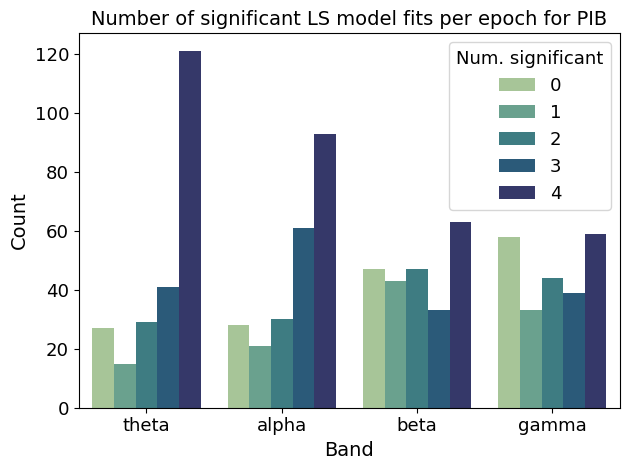

In [17]:
ax = sns.countplot(data=pvaluecounts, x='band', hue='sigcycles', order=band_list, palette='crest')

# format legend
ax.legend(loc='upper right', title='Num. significant', fontsize=13, title_fontsize=13)

plt.xlabel('Band', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.tick_params(labelsize=13)

plt.title('Number of significant LS model fits per epoch for PIB', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'pib_num_sig_per_epoch.pdf', dpi=300)

plt.show()

### Amplitude distribution

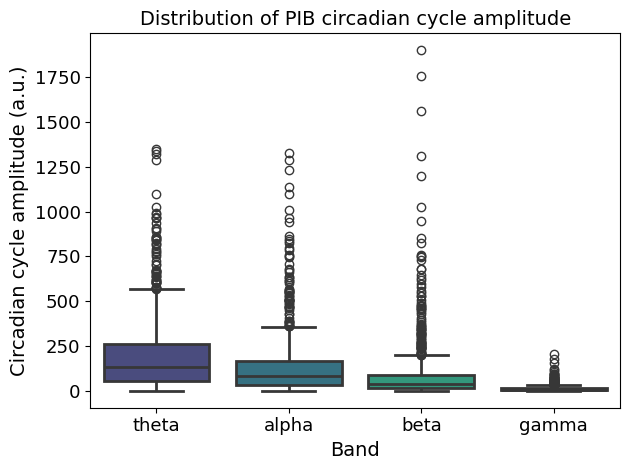

In [18]:
sns.boxplot(data=charsdf.loc[charsdf['charac']=='amp_unnorm'], x='band', y='value', hue='band', legend=False, 
            order=band_list, palette='viridis', linewidth=2)

plt.xlabel('Band', fontsize=14)
plt.ylabel('Circadian cycle amplitude (a.u.)', fontsize=14)
plt.tick_params(labelsize=13)

plt.title('Distribution of PIB circadian cycle amplitude', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'pib_amplitude_boxplot.pdf', dpi=300)

plt.show()

### Distribution of peak phase

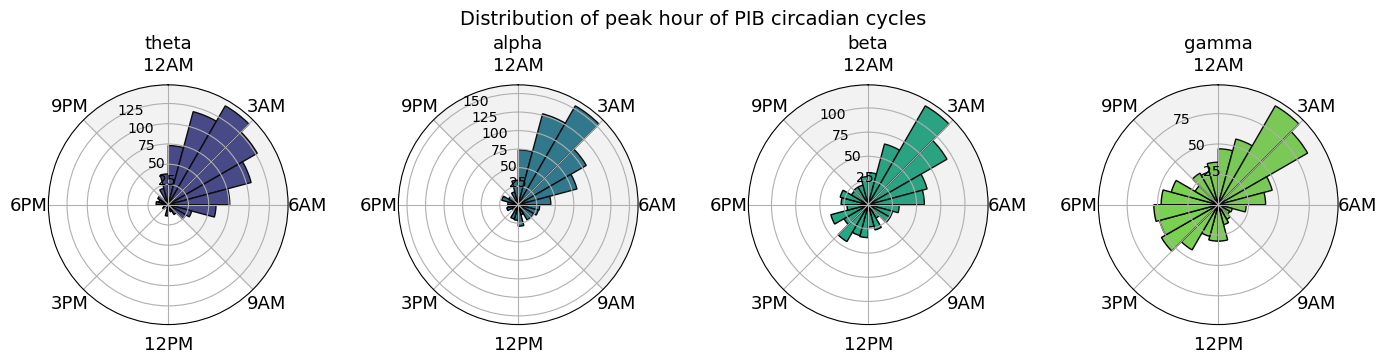

In [19]:
nrows = 1
ncols = len(band_list)

time_low, time_high = 9, 21
viridis_colors = sns.color_palette(palette='viridis', n_colors=4)

# Create polar subplot
fig, ax = plt.subplots(nrows, ncols, figsize=(3.5*ncols, 3.5*nrows), subplot_kw={'projection': 'polar'}, layout='constrained')

for ii in range(len(ax)):
    # data of given band
    cycle_peak_hours = charsdf.loc[(charsdf['charac']=='peakhour') & (charsdf['band']==band_list[ii])]['value'].values
        
    # Create histogram
    ax[ii].hist(np.pi/12 * cycle_peak_hours, bins=np.linspace(0, 2*np.pi, 25), 
                color=viridis_colors[ii], edgecolor='k', alpha=1.0)
    
    ax[ii].axvspan(xmin=(time_high-24) * np.pi/12, xmax=time_low * np.pi/12, color='grey', alpha=0.1)
    
    # Customize plot
    ax[ii].set_theta_zero_location("N")  # Set 0 at the top
    ax[ii].set_theta_direction(-1)      # Clockwise direction
    ax[ii].set_xticks(ticks=[0, np.pi/4, 2*np.pi/4, 3*np.pi/4, 
                         np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4], 
                  labels=['12AM', '3AM', '6AM', '9AM', 
                          '12PM', '3PM', '6PM', '9PM'], fontsize=13)
    ax[ii].set_yticks(ticks=np.arange(25, ax[ii].get_ylim()[1], 25))
    ax[ii].set_rlabel_position(-30)

    # asethetics
    ax[ii].set_title(band_list[ii], fontsize=13)

fig.suptitle('Distribution of peak hour of PIB circadian cycles', fontsize=14)

if save_flag:
    plt.savefig(outsupfig_dir + 'pib_cc_peak_dist_all_bands.pdf', dpi=300)

plt.show()

## PIB-CC with outcome

In [20]:
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']
tltype = 'causal'  # 'causal' or 'noncausal'
mreg_id_vars = ['npecode', 'feat_days', 'baseline_seizure_rate', 'outcome_days', 'sz_red',
                'auc', 'auc_interval', 'auc_converse', 'max_hour', 'sin_hour', 'cos_hour']
mreg_value_vars = ['amp_unnorm_local', 'peakhour_local']

# FC-CC features
lgfeatdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, patient_list, band_list, edge_type_list, subfeatdict)

# combine stimulation feature with FC-CC features
lgfeatdf = lgaucdf.merge(lgfeatdf, how='left', left_on=['npecode', 'dur_day'],
                     right_on=['npecode', 'days_from_implant'])

# combine features with seizure reduction information
mregdf = ccutils.create_cop_dataframe(lgpatcodesdf, lgfeatdf, patient_list, mreg_id_vars, mreg_value_vars, tltype, 
                                      verbose=True)

print('Num samples:', mregdf.shape[0])

Dropped nans in regdf: 0
Num samples: 72


In [21]:
pearsonr(mregdf['sz_red'], mregdf['peakhour_local-alpha'])

PearsonRResult(statistic=-0.29168530894586386, pvalue=0.012917601693188317)

### Circadian biomarker plot

PearsonRResult(statistic=-0.29168530894586386, pvalue=0.012917601693188317)
Num samples: 72


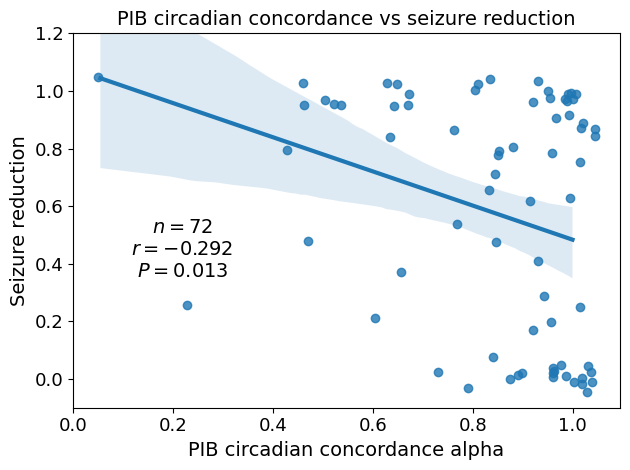

In [22]:
xfeat = 'peakhour_local-alpha'
yvar = 'sz_red'
band = xfeat.split('-')[-1]

xcorr = mregdf[xfeat].values
ycorr = mregdf[yvar].values
n_samp = len(xcorr)

corrres = pearsonr(xcorr, ycorr)
print(corrres)
print(f'Num samples: {len(xcorr)}')

# model prediction
ax = sns.regplot(data=mregdf, x=xfeat, y=yvar, line_kws={'linewidth':3}, 
                 x_jitter=0.05, y_jitter=0.05)

# annotations
ax.text(x=0.2, y=0.35, s='$n=%d$\n$r=%0.3f$\n$P=%0.3f$'%(n_samp, corrres.statistic, corrres.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
plt.xlabel(f'PIB circadian concordance {band}', fontsize=14)
plt.ylabel('Seizure reduction', fontsize=14)
plt.tick_params(labelsize=13)
ax.set_ylim([-0.1, 1.2])

plt.title('PIB circadian concordance vs seizure reduction', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + f'pib_cc_{band}_scatterplot_jittered.pdf', dpi=300)

plt.show()

PearsonRResult(statistic=-0.34981543553341093, pvalue=0.0025943116475415657)
Num samples: 72


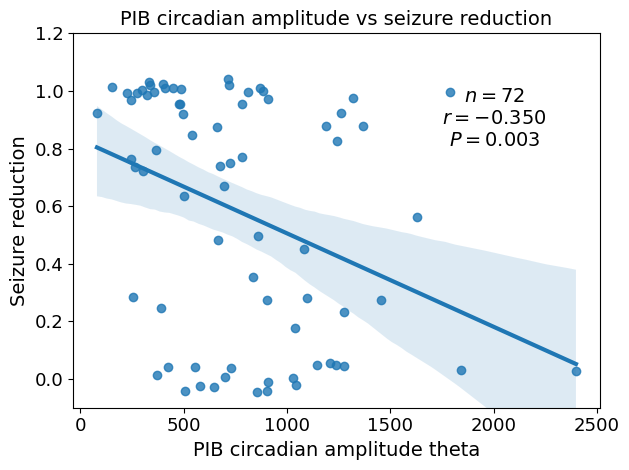

In [23]:
xfeat = 'amp_unnorm_local-theta'
yvar = 'sz_red'
band = xfeat.split('-')[-1]

xcorr = mregdf[xfeat].values
ycorr = mregdf[yvar].values
n_samp = len(xcorr)

corrres = pearsonr(xcorr, ycorr)
print(corrres)
print(f'Num samples: {len(xcorr)}')

# model prediction
ax = sns.regplot(data=mregdf, x=xfeat, y=yvar, line_kws={'linewidth':3}, 
                 x_jitter=0.0, y_jitter=0.05)

# annotations
ax.text(x=0.8, y=0.7, s='$n=%d$\n$r=%0.3f$\n$P=%0.3f$'%(n_samp, corrres.statistic, corrres.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
plt.xlabel(f'PIB circadian amplitude {band}', fontsize=14)
plt.ylabel('Seizure reduction', fontsize=14)
plt.tick_params(labelsize=13)
ax.set_ylim([-0.1, 1.2])

plt.title('PIB circadian amplitude vs seizure reduction', fontsize=14)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + f'pib_ca_{band}_scatterplot_jittered.pdf', dpi=300)

plt.show()

### recursive feature selection

In [24]:
# recusive feature elimination for a range of feature sets

feat_sz = ['log_baseline_seizure_rate']

feat_fccc_amp = ['amp_unnorm_local-theta', 'amp_unnorm_local-alpha', 
                 'amp_unnorm_local-beta', 'amp_unnorm_local-gamma']

feat_fccc_ps = ['peakhour_local-theta', 'peakhour_local-alpha', 
                'peakhour_local-beta', 'peakhour_local-gamma']

feat_stim = ['auc_interval', 'auc_converse', 'sin_hour', 'cos_hour']

feat_all = feat_sz + feat_fccc_amp + feat_fccc_ps + feat_stim

fullfeatdict = {'sz': feat_sz , 'fccc_amp': feat_fccc_amp, 'fccc_ps': feat_fccc_ps, 
                'fccc': feat_fccc_amp + feat_fccc_ps, 'stim': feat_stim, 'all': feat_all}

yvar = 'sz_red'

rfefeatdict = {}

for featkey, regfeats in fullfeatdict.items():
    print(featkey)
    # recursive feature elimination
    final_regfeats = linearreg.recursive_feature_elimination(regdf=mregdf, full_feature_list=regfeats, yvar=yvar, 
                                                             cv_folds_list=patient_list, cv_var='npecode', 
                                                             remove_outliers=False)

    print('Final feature list:', final_regfeats)
    
    # store the features
    rfefeatdict[featkey] = final_regfeats

sz
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue    0
dtype: int64
Final feature list: []
fccc_amp
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    1
amp_unnorm_local-alpha__pvalue    0
amp_unnorm_local-beta__pvalue     0
amp_unnorm_local-gamma__pvalue    1
dtype: int64
Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    3
amp_unnorm_local-gamma__pvalue    0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    30
dtype: int64
Final feature list: ['amp_unnorm_local-theta']
fccc_ps
Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 peakhour_local-theta__pvalue     0
peakhour_local-alpha__pvalue    28
peakhour_local-beta__pvalue      0
peakhour_local-gamma__pvalue     0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 peakhour_local-alpha__pvalue    29
dtype: int64
Final feature list: ['peakhour_local-alpha']
fccc
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue     2
amp_unnorm_local-alpha__pvalue     0
amp_unnorm_local-beta__pvalue      0
amp_unnorm_local-gamma__pvalue     1
peakhour_local-theta__pvalue      24
peakhour_local-alpha__pvalue       2
peakhour_local-beta__pvalue        0
peakhour_local-gamma__pvalue       0
dtype: int64
Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    10
amp_unnorm_local-gamma__pvalue     0
peakhour_local-theta__pvalue      29
peakhour_local-alpha__pvalue      29
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 amp_unnorm_local-theta__pvalue    30
peakhour_local-theta__pvalue      29
peakhour_local-alpha__pvalue      29
dtype: int64
Final feature list: ['amp_unnorm_local-theta', 'peakhour_local-theta', 'peakhour_local-alpha']
stim
Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 auc_interval__pvalue     0
auc_converse__pvalue    30
sin_hour__pvalue         1
cos_hour__pvalue         0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 auc_converse__pvalue    30
sin_hour__pvalue         0
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 auc_converse__pvalue    30
dtype: int64
Final feature list: ['auc_converse']
all
Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue     2
amp_unnorm_local-theta__pvalue        3
amp_unnorm_local-alpha__pvalue        0
amp_unnorm_local-beta__pvalue         0
amp_unnorm_local-gamma__pvalue        2
peakhour_local-theta__pvalue          6
peakhour_local-alpha__pvalue          0
peakhour_local-beta__pvalue           0
peakhour_local-gamma__pvalue          0
auc_interval__pvalue                  0
auc_converse__pvalue                 29
sin_hour__pvalue                      0
cos_hour__pvalue                      1
dtype: int64
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue     1
amp_unnorm_local-theta__pvalue       28
amp_unnorm_local-gamma__pvalue        0
peakhour_local-theta__pvalue          0
auc_converse__pvalue                 30
cos_hour__pvalue                      0
dt

Clipped output between 0-1.
Cross-validation complete.
Significance counts of each feature:
 log_baseline_seizure_rate__pvalue     1
amp_unnorm_local-theta__pvalue       29
auc_converse__pvalue                 30
dtype: int64
Final feature list: ['log_baseline_seizure_rate', 'amp_unnorm_local-theta', 'auc_converse']


In [25]:
## include baseline seizure rate
rfefeatdict['sz'] = ['log_baseline_seizure_rate']

yvar = 'sz_red'


gppreddf = []  # all the predictions for all the feature sets
gpmsedf = []   # MSE for each fold for all the feature sets
cmmsedf = []   # grand total MSE (combined MSE) for all the feature sets
cmllfdf = []   # combined log likelihood of trained model for all the feature sets

for featkey, regfeats in rfefeatdict.items():
    
    print(f'\n{featkey}')
    
    # linear regression cross-validation
    lmpreddf, linmoddict = linearreg.cross_validation(regdf=mregdf, regfeat_cols=regfeats, yvar=yvar, 
                                                     cv_folds_list=patient_list, cv_var='npecode', 
                                                     remove_outliers=False)
    
    # store predictions
    if featkey == 'sz':
        gppreddf.append(lmpreddf.rename(columns={'modpred':featkey}))
    else:
        gppreddf.append(lmpreddf['modpred'].rename(featkey))
    
    # compute MSE
    if featkey == 'sz':
        diff_tuples = [('gt','modpred', f'{featkey}_mse'), ('gt','basemean','base_mse')]
    else:
        diff_tuples = [('gt','modpred', f'{featkey}_mse')]
        
    lmmsedf = linearreg.foldwise_mse(preddf=lmpreddf, cv_var='npecode', diff_tuples=diff_tuples)
    
    feat_cmmsedf = linearreg.combined_mse(preddf=lmpreddf, diff_tuples=diff_tuples)
    
    gpmsedf.append(lmmsedf.copy())
    cmmsedf.append(feat_cmmsedf)
    
    # number of times a coefficient was significant
    lmsummary = linearreg.summarize_model_cv(linmoddict, cv_var='npecode')
    print((lmsummary[[item for item in lmsummary.columns if '__pvalue' in item]] < 0.05).sum())
    
    # combined loglikeihood of training data
    cmllfdf.append(pd.DataFrame({featkey: [linearreg.combined_llf(linmoddict)]}))

# concatenate
gppreddf = pd.concat(gppreddf, axis=1, ignore_index=False)
gpmsedf = pd.concat(gpmsedf, axis=1, ignore_index=False)
cmmsedf = pd.concat(cmmsedf, axis=1, ignore_index=False)
cmllfdf = pd.concat(cmllfdf, axis=1, ignore_index=False)


sz
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
log_baseline_seizure_rate__pvalue     0
const__pvalue                        30
dtype: int64

fccc_amp
Outliers NOT removed. Num entries: 72.


Clipped output between 0-1.
Cross-validation complete.
amp_unnorm_local-theta__pvalue    30
const__pvalue                     30
dtype: int64

fccc_ps
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
peakhour_local-alpha__pvalue    29
const__pvalue                   30
dtype: int64



fccc
Outliers NOT removed. Num entries: 72.


/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[0]] - x[tup[1]]) ** 2).mean() )
/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[

Clipped output between 0-1.
Cross-validation complete.
amp_unnorm_local-theta__pvalue    30
peakhour_local-theta__pvalue      29
peakhour_local-alpha__pvalue      29
const__pvalue                     30
dtype: int64

stim
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
auc_converse__pvalue    30
const__pvalue           30
dtype: int64

all
Outliers NOT removed. Num entries: 72.
Clipped output between 0-1.
Cross-validation complete.
log_baseline_seizure_rate__pvalue     1
amp_unnorm_local-theta__pvalue       29
auc_converse__pvalue                 30
const__pvalue                        30
dtype: int64


/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[0]] - x[tup[1]]) ** 2).mean() )
/Users/saboo/Projects/pub-2026-circadian-cycle-rns-control/src/model/linearreg.py:105: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  modmsedf = preddf.groupby(by=cv_var).apply(lambda x: ((x[tup[

In [26]:
rfefeatdict

{'sz': ['log_baseline_seizure_rate'],
 'fccc_amp': ['amp_unnorm_local-theta'],
 'fccc_ps': ['peakhour_local-alpha'],
 'fccc': ['amp_unnorm_local-theta',
  'peakhour_local-theta',
  'peakhour_local-alpha'],
 'stim': ['auc_converse'],
 'all': ['log_baseline_seizure_rate',
  'amp_unnorm_local-theta',
  'auc_converse']}

### Clinical Prediction MSE Comparison

In [27]:
cmmsedf_norm = 100 * (cmmsedf['base_mse'].item() - cmmsedf) / cmmsedf['base_mse'].item()
mse_xtldict = {'sz': 'Sz.', 'fccc_amp': 'CA', 'fccc_ps': 'CC', 
               'fccc': 'CA and CC', 'stim': 'Stim.', 'all': 'All'}

# non filtered cmmsedf norm for PLV (from Figure 2 file)
cmmsedf_norm_plv = pd.DataFrame(
    {'sz_mse': {0: -7.0322146547431625},
     'fccc_amp_mse': {0: 0.0},
     'fccc_ps_mse': {0: 8.511233536657018},
     'fccc_mse': {0: 14.310578030858673},
     'stim_mse': {0: 11.508900816625133},
     'all_mse': {0: 21.285417608376182}})

In [28]:
# combine all / sig cycle performances for comparison
cmmsedf_both = pd.concat((cmmsedf_norm.T.rename(columns={0:'pib'}), 
                          cmmsedf_norm_plv.T.rename(columns={0:'plv'})), axis=1, ignore_index=False)
cmmsedf_both.reset_index(names='feats', inplace=True)
cmmsedf_both = cmmsedf_both.melt(id_vars='feats', value_vars=['pib', 'plv'], var_name='cycletype', value_name='mse')
cmmsedf_both.drop(index=cmmsedf_both.index[cmmsedf_both['feats']=='base_mse'], inplace=True)

/var/folders/gd/6nx8h5_s2pl0kp6dz_b6wn300000gn/T/ipykernel_46460/2307349187.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])


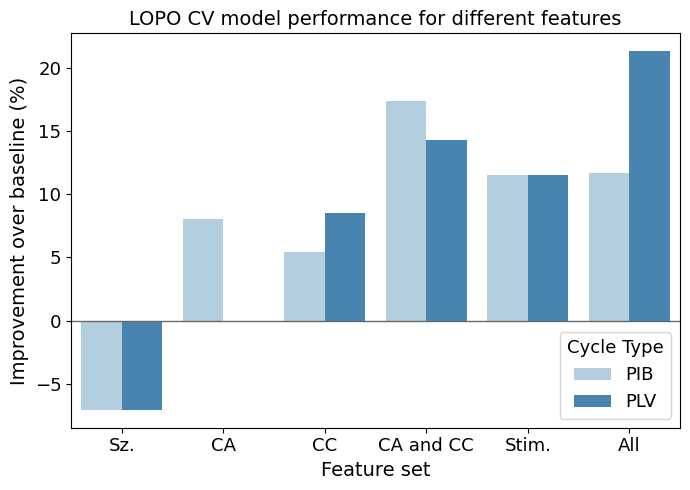

In [29]:
feature_set_list = ['sz_mse', 'fccc_amp_mse', 'fccc_ps_mse', 'fccc_mse', 'stim_mse', 'all_mse']

fig, ax = plt.subplots(1,1, figsize=(7,5))
sns.barplot(data=cmmsedf_both, x='feats', y='mse', hue='cycletype', hue_order=['pib', 'plv'], 
            ax=ax, palette='Blues')
ax.axhline(y=0, linewidth=1, color='dimgray')

# format legend
moleghan, moleglab = ax.get_legend_handles_labels()
moleglab = ['PIB', 'PLV']
ax.legend(moleghan, moleglab, loc='lower right', title='Cycle Type', 
          fontsize=13, title_fontsize=13)

ax.set_xticklabels(labels=[mse_xtldict[item.split('_mse')[0]] for item in feature_set_list])
ax.set_xlabel('Feature set', fontsize=14)
ax.set_ylabel('Improvement over baseline (%)', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title('LOPO CV model performance for different features', fontsize=14)

fig.tight_layout()

if save_flag:
    fig.savefig(outsupfig_dir + 'pib_clinpred_mse.pdf', dpi=300)

plt.show()
